**At the start of each notebook there will be 3 - 5 cells of code that need to be run before the rest of the notebook. These cells make sure we have imported all the required Python packages so that we can run the rest of the code without issue!**
- If you do not have these packages, you will need to pip install them. 

In [3]:
import numpy as np # Numpy is used for math and stats in python 
import pandas as pd # Pandas is used for handling data in a spreadsheet like way
import matplotlib.pyplot as plt  # Matplotlib is used for plotting
import seaborn as sns # Seaborn is another plotting package 



In [4]:
## Matt has made a lot of improvements over the last week as we put together this workshop - run this upgrade! Then restart your kernel
#%pip install --upgrade petthermotools

In [5]:
# If the alphaMELTS for Python files have not been added to your Python path (see installation guide) then use the two lines below to add
# the location of the alphaMELTS files here.
# import sys
# sys.path.append(r'C:\Users\penny\Box\Berkeley_new\MELTS_Installation\alphamelts_py\alphamelts-py-2.3.1-win64')


import petthermotools as ptt 

print(ptt.__version__)

alphaMELTS for Python files successfully located.
If you are planning on using the Green et al. (2025) or Weller et al. (2024) thermodynamic models through MAGEMin for crystallization, melting, or phase diagram calculations 
you will need to run `ptt.activate_petthermotools_env()` at the start of each notebook, prior to any calculations, every time you restart the kernel. 
This step establishes the python-julia connection and sets up the julia workers. Expect it to take about 20-40s on most machines. 
NOTE - once `ptt.activate_petthermotools_env()` has been run you WILL NOT be able to run any calculations with the MELTS models. It is my recommendation that Windows 
users run the MAGEMin models in one notebook and the MELTS models in another notebook. I'm actively working to try and find a way around this.
nGibbs not installed — nGibbs emulators are unavailable. Install it if you'd like with `ptt.install_nGibbs()` (~300 MB storage required).
1.3.7


# Part 1 - Lets load in a melt inclusion dataset

First, we load in melt inclusion data from various arc volcanoes around the world (data taken from the supplement of Rasmussen et al. 2022).

In [6]:
# load in the excel sheet with the melt inclusion data
MI_All = pd.read_excel('MI_Arcs.xlsx', sheet_name='Data')
MI_All = MI_All.fillna(0.0)
print(type(MI_All))
MI_All.head()

<class 'pandas.DataFrame'>


,Sample,Volcano,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,...,Ho,Er,Yb,Lu,Hf,Ta,W,Pb,Th,U
0,Agr07-1,Agrigan,51.33,0.98,17.13,9.254514,0.15,5.29,12.06,2.51,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Agr07-4,Agrigan,45.45,0.65,17.27,10.191446,0.23,5.54,12.32,1.75,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Agr07-5,Agrigan,48.17,0.72,19.25,10.307459,0.23,5.64,12.25,2.51,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Agr07-6,Agrigan,48.46,0.71,19.10,10.247438,0.22,5.11,13.26,2.10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Agr07-7,Agrigan,50.98,0.90,17.94,9.094535,0.17,4.88,12.44,2.56,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


We can also start to think about what data we do, or don't, want for our calculations. In this notebook we'll use the H2O (and CO2 when present) contents of the melt inclusions to assess the apparent entrapment depths (issues relating to water loss by diffusion and/or missed CO2 in the glass phase or a vapor bubble might affect these calculations). For these calculations we are only really interested in melt inclusions where H2O has been measured. Let's 'filter' our DataFrame to only include rows with H2O contents greater than 0.0.

Running the second line (**.reset_index()**) helps to ensure that the row (or index) numbers run continuously without jumps/gaps (i.e., from 0 to n).

In [7]:
H2O_Filt=MI_All['H2O_Liq'] > 0
CO2_Filt=MI_All['CO2_Liq'] > 0
MI_Filt =MI_All[H2O_Filt&CO2_Filt]

In [8]:
MI_Filt

,Sample,Volcano,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,...,Ho,Er,Yb,Lu,Hf,Ta,W,Pb,Th,U
1,Agr07-4,Agrigan,45.450000,0.650000,17.270000,10.191446,0.230000,5.540000,12.320000,1.750000,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
5,Agr07-9,Agrigan,48.200000,0.760000,17.290000,9.137500,0.180000,4.820000,12.080000,2.210000,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
13,Agr07-15A,Agrigan,47.720000,0.810000,16.730000,10.668378,0.220000,5.660000,11.330000,2.310000,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
14,Agr07-15B,Agrigan,47.970000,0.860000,16.830000,10.419421,0.190000,5.550000,11.330000,2.350000,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
22,Agr04-13,Agrigan,50.940000,0.800000,16.720000,8.826560,0.200000,4.860000,10.160000,2.730000,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3430,WD07MI02,Westdahl,48.045006,1.362950,18.855640,9.566860,0.191507,4.285474,11.548947,3.457796,...,0.0,2.285127,2.178691,0.311211,0.0,0.0,0.0,2.798290,1.178232,0.496701
3442,WD12MI01,Westdahl,45.613489,1.354230,17.470442,10.608287,0.205108,5.639896,13.078534,2.499807,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
3443,WD12MI02,Westdahl,46.717879,1.337548,18.683351,10.185628,0.192082,4.894018,11.716153,3.004943,...,0.0,2.136697,2.300904,0.364029,0.0,0.0,0.0,2.660209,1.339774,0.514887
3463,WD71AMI03,Westdahl,47.622249,1.027603,18.917310,11.130538,0.200821,5.324016,8.300835,3.256045,...,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000


## Lets look at just a single volcano

In [9]:
Agrigan=MI_Filt[MI_Filt['Volcano']=='Agrigan']

In [12]:
# Assess volatile saturation pressure and liquidus temperature of the melt inclusions.
Sat_P = ptt.saturation_pressure(Model = "MELTSv1.2.0",
                          bulk = Agrigan.reset_index(drop=True),
                          T_fixed_C= 1200,
                          P_init_bar=4000,
                          fO2_buffer="FMQ",
                          fO2_offset=2, 
                          timeout=45,
                          copy_columns=['Volcano', 'Sample']
                        )

# Talk through the copy_columns=['Sample', 'Volcano'] functionality as an alternative, so you copy things over from the original dataframe you might want. 



saturation_pressure_v2:   0%|          | 0/16 [00:00<?, ?it/s]

saturation_pressure_v2: 16/16 converged, 0 did not (any failure is retried up to 1 time(s), at 2.0x timeout and a perturbed starting guess each round).


## Lets look at what happens when we crystallize a magma with a mixed fluid composition

In [35]:
max_CO2_Ag = Sat_P.loc[Sat_P["CO2_Liq"].idxmax()]
print(max_row['H2O_Liq'])
print(max_row['CO2_Liq']*10**4)

3.5
449.0


## Lets inspect the outputs from this

In [37]:

Isobaric_Xtal = ptt.isobaric_crystallisation(Model = "MELTSv1.2.0",
                                           bulk = max_CO2_Ag,
                                           find_liquidus = True,
                                           P_bar = max_CO2_Ag['P_bar'],
                                           T_end_C = 1000,
                                           dt_C = 2,
                                           fO2_buffer = "FMQ",
                                           fO2_offset = 1.0,
                                           Frac_solid = True,
                                           Frac_fluid = True,
                                           label = "P_bar")

multi_path_v2: timeout not specified, using the platform default of 180s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).


In [55]:
## lets also calculate water as if totally incompatible

H2O_init =Isobaric_Xtal['All']['H2O_Liq'].iloc[0]  # starting H2O in wt%, set this to your value

m_liq = Isobaric_Xtal['mass_g']['liquid1']
F = m_liq / m_liq.iloc[0]          # melt fraction relative to the first step
H2O_incomp = H2O_init / F

## Lets plot H2O and CO2 vs MgO

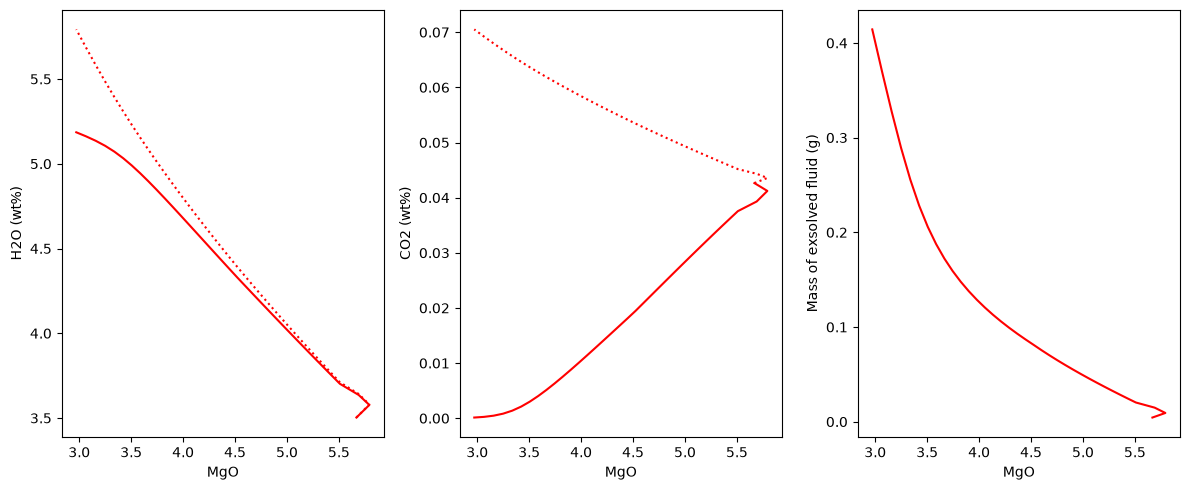

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12,5))
ax1.plot(Isobaric_Xtal['All']['MgO_Liq'], Isobaric_Xtal['All']['H2O_Liq'], '-r', label='volatile sat FC')
ax1.plot(Isobaric_Xtal['All']['MgO_Liq'], H2O_incomp, ':r', label='Incompatible crystallization')
ax1.set_xlabel('MgO')
ax1.set_ylabel('H2O (wt%)')

## TO DO - Add a panel for CO2 and and incompatible fractionation for CO2

ax2.set_xlabel('MgO')
ax2.set_ylabel('CO2 (wt%)')

## TO DO - Add a panel for cumulative sum of fluid in the 'mass_g' part of the dictionary


ax3.set_xlabel('MgO')
ax3.set_ylabel('Mass of exsolved fluid (g)')


plt.tight_layout()

## We can look at this fluid composition

In [43]:
Isobaric_Xtal['fluid1'].head()

,H2O_Fl,CO2_Fl,X_H2O_mol_Fl,X_CO2_mol_Fl
0,50.804321,49.195679,0.716262,0.283738
1,51.348079,48.651921,0.720663,0.279337
2,51.893959,48.106041,0.725042,0.274958
3,52.441927,47.558073,0.729398,0.270602
4,52.991949,47.008051,0.733732,0.266268


## Make a plot of fluid composition (X_H2O) vs. MgO ()

In [ ]:
plt.plot()

## Lets ascend the magma towards the surface

In [66]:
max_H2O_Ag = Sat_P.loc[Sat_P["H2O_Liq"].idxmax()]

In [67]:
# This is closed system because we aren't fractionating fluids
decompress_closed = ptt.isothermal_decompression(Model="MELTSv1.2.0",
    bulk=max_H2O_Ag, find_liquidus=True, fO2_buffer="FMQ", fO2_offset=1,
    P_start_bar=max_H2O_Ag['P_bar'], P_end_bar=50, dp_bar=20, fluid_sat = True,
    Frac_fluid=False, Frac_solid=False)

decompress_open = ptt.isothermal_decompression(Model="MELTSv1.2.0",
    bulk=max_H2O_Ag , find_liquidus=True, fO2_buffer="FMQ", fO2_offset=1,
    P_start_bar=max_H2O_Ag['P_bar'], P_end_bar=50, dp_bar=20, fluid_sat = True,
    Frac_fluid=True, Frac_solid=False)

multi_path_v2: timeout not specified, using the platform default of 180s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).
multi_path_v2: timeout not specified, using the platform default of 180s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).


(<Figure size 400x500 with 1 Axes>,
 <Axes: xlabel='Mass fraction', ylabel='Pressure (bar)'>)

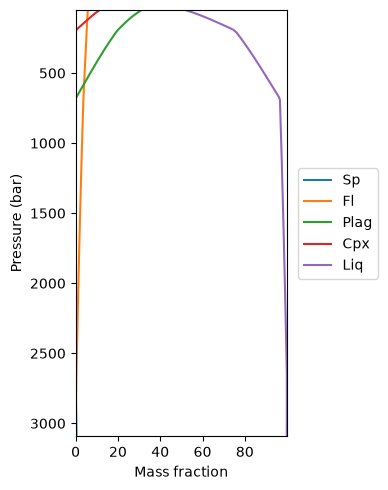

In [ ]:
ptt.phase_plot(decompress_closed, y_axis='P_bar', lines=True)

## Lets plot up H2O vs. CO2 for both these to start

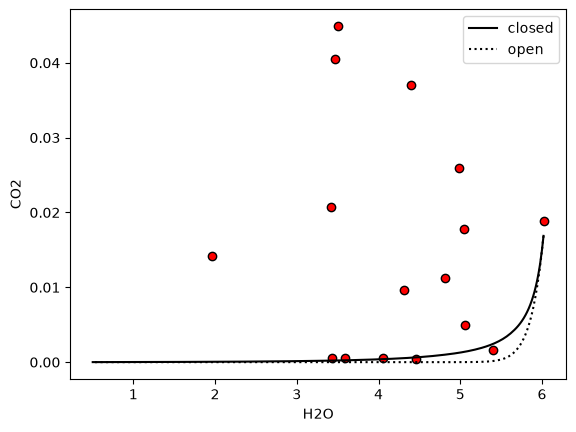

In [ ]:
plt.plot(Agrigan['H2O_Liq'], Agrigan['CO2_Liq'], 'ok', mfc='red')
plt.plot(decompress_closed['All']['H2O_Liq'], 
         decompress_closed['All']['CO2_Liq'], '-k', label='closed',
)
# Add the model you just ran


plt.xlabel('H2O')
plt.ylabel('CO2')
plt.legend()

## Lets look at the major elements

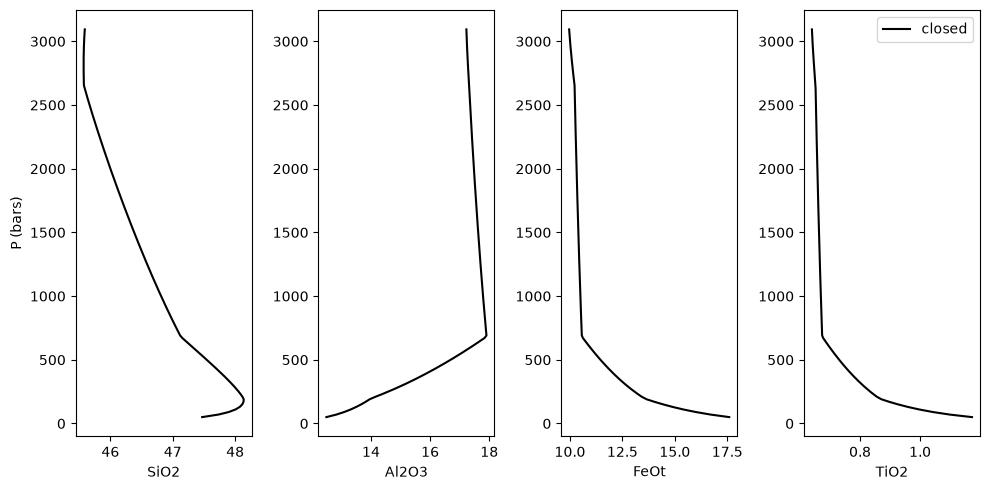

In [103]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(10,5))
ax1.plot(decompress_closed['All']['SiO2_Liq'], 
         decompress_closed['All']['P_bar'], '-k', label='closed',
)
ax2.plot(decompress_closed['All']['Al2O3_Liq'], 
         decompress_closed['All']['P_bar'], '-k', label='closed',
)

ax3.plot(decompress_closed['All']['FeOt_Liq'], 
         decompress_closed['All']['P_bar'], '-k', label='closed',
)

ax4.plot(decompress_closed['All']['TiO2_Liq'], 
         decompress_closed['All']['P_bar'], '-k', label='closed',
)
# plt.plot(decompress_open['All']['H2O_Liq'], 
#          decompress_open['All']['CO2_Liq'], ':k', label='open'
# )
ax1.set_xlabel('SiO2')
ax2.set_xlabel('Al2O3')
ax3.set_xlabel('FeOt')
ax4.set_xlabel('TiO2')
ax1.set_ylabel('P (bars)')
plt.legend()
fig.tight_layout()

## What phases are causing this?

In [89]:
decompress_closed['mass_g'].head()

,clinopyroxene1,fluid1,liquid1,plagioclase1,spinel1
0,0.0,0.000000,99.824524,0.0,0.431124
1,0.0,0.008580,99.831376,0.0,0.415280
2,0.0,0.019243,99.836551,0.0,0.399015
3,0.0,0.030601,99.841333,0.0,0.382438
4,0.0,0.042693,99.845703,0.0,0.365527


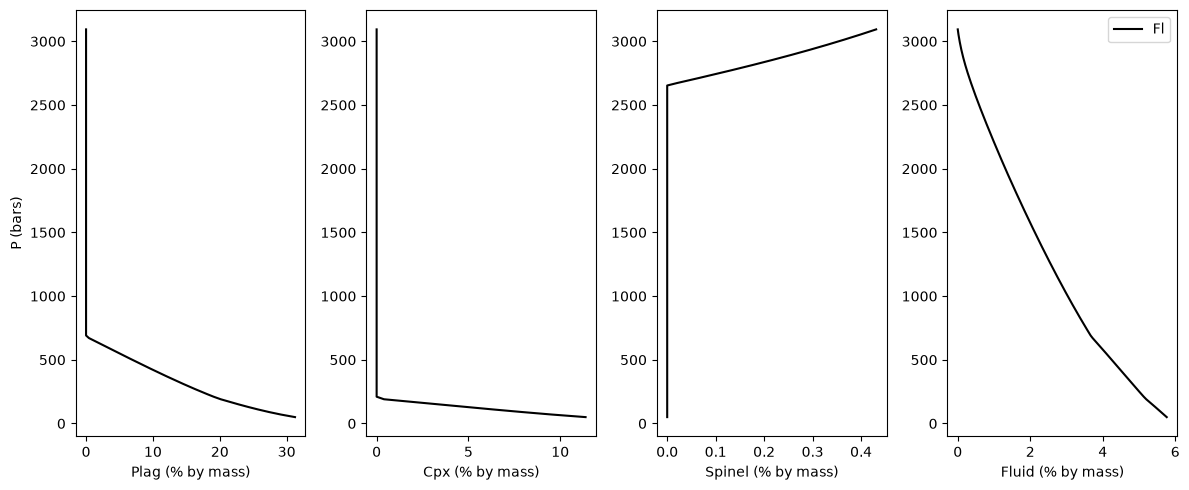

In [ ]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(12,5))
# Add a plot of mass of these phases vs. Pressure fo rPlag, Cpx, Spinel and fluid

ax1.set_xlabel('Plag (% by mass)')
ax2.set_xlabel('Cpx (% by mass)')
ax3.set_xlabel('Spinel (% by mass)')
ax4.set_xlabel('Fluid (% by mass)')
ax1.set_ylabel('P (bars)')
plt.legend()
fig.tight_layout()

## do the same by volume

In [98]:
decompress_closed['volume_cm3'].head()

,clinopyroxene1,fluid1,liquid1,plagioclase1,spinel1
0,0.0,0.000000,41.963236,0.0,0.099466
1,0.0,0.020749,41.962483,0.0,0.095784
2,0.0,0.046806,41.959144,0.0,0.092009
3,0.0,0.074863,41.954924,0.0,0.088165
4,0.0,0.105045,41.949776,0.0,0.084247


In [99]:
# NEed to sum them as doesnt sum to 100 like mass
vol = decompress_closed['volume_cm3']
vol['total'] = vol.sum(axis=1)

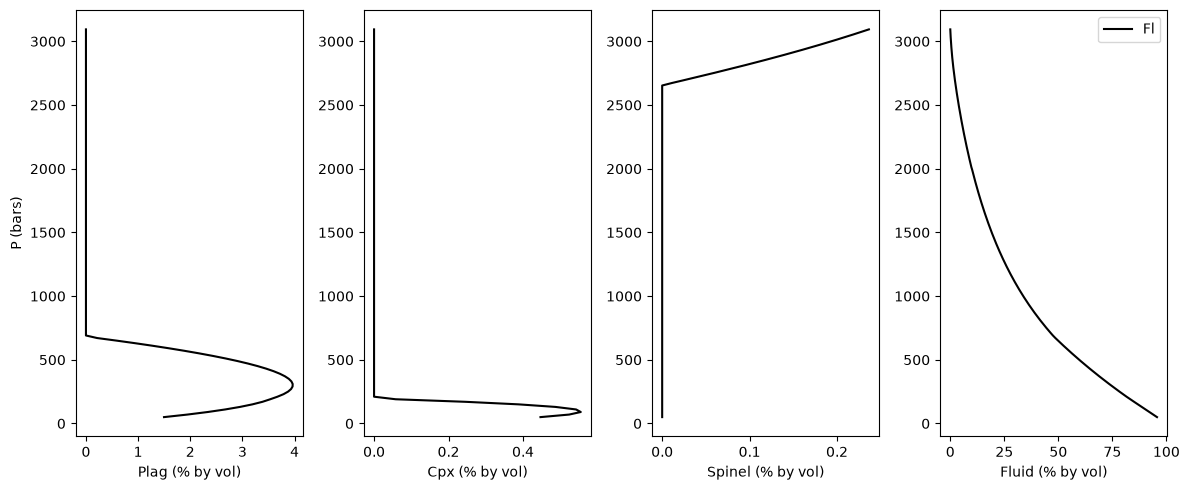

In [ ]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(12,5))
## volume code here. 
# )
ax1.set_xlabel('Plag (% by vol)')
ax2.set_xlabel('Cpx (% by vol)')
ax3.set_xlabel('Spinel (% by vol)')
ax4.set_xlabel('Fluid (% by vol)')
ax1.set_ylabel('P (bars)')
plt.legend()
fig.tight_layout()